# Modèles linéaires généralisés (GLM) : la régression linéaire réinventée

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/modeles-lineaires-generalises-glm/modeles-lineaires-generalises-glm.ipynb)

📖 **Le mini-cours complet** : [Modèles Linéaires Généralisés (GLM) : la régression linéaire réinventée](https://www.monshotdata.com/p/modeles-lineaires-generalises-glm)

🧭 **Le cours** : [ML classique et Deep Learning › 2.2 Régression et classification](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc22)

---

Régression linéaire, régression logistique, régression de Poisson : trois modèles que l'on apprend séparément… alors qu'ils sont **le même modèle** avec trois réglages différents. Ce notebook te le montre en code, sur des données simulées que tu peux modifier à volonté.

**À la fin de ce notebook, tu sauras :**

- reconnaître une régression linéaire, logistique ou de Poisson comme un seul et même GLM (une loi + une fonction de lien) ;
- choisir la bonne famille de modèles selon la nature de ta variable cible (continue, binaire, comptage) ;
- construire ton propre GLM avec `statsmodels` quand aucun modèle « standard » ne colle à tes données.


### Avant de lancer

Aucun fichier externe, aucun GPU : **Exécution → Tout exécuter** (une dizaine de secondes). Les données sont simulées aléatoirement, tes graphiques varieront donc légèrement d'une exécution à l'autre.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, NumPy, scikit-learn, statsmodels et Matplotlib dans leurs versions de Colab.*

## 1. Mise en place

On importe les librairies et on fixe deux couleurs réutilisées dans tous les graphiques.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, PoissonRegressor
from scipy.stats import poisson

sns.set()

In [2]:
colors = ['#fe7c73', '#2471A3']

## 2. Régression linéaire : le point de départ

On simule une relation linéaire y = 3x + 2 avec un bruit gaussien d'écart-type 4. C'est exactement le cadre où la régression linéaire est à l'aise : la sortie est continue, son bruit est gaussien et sa variance ne dépend pas de x.

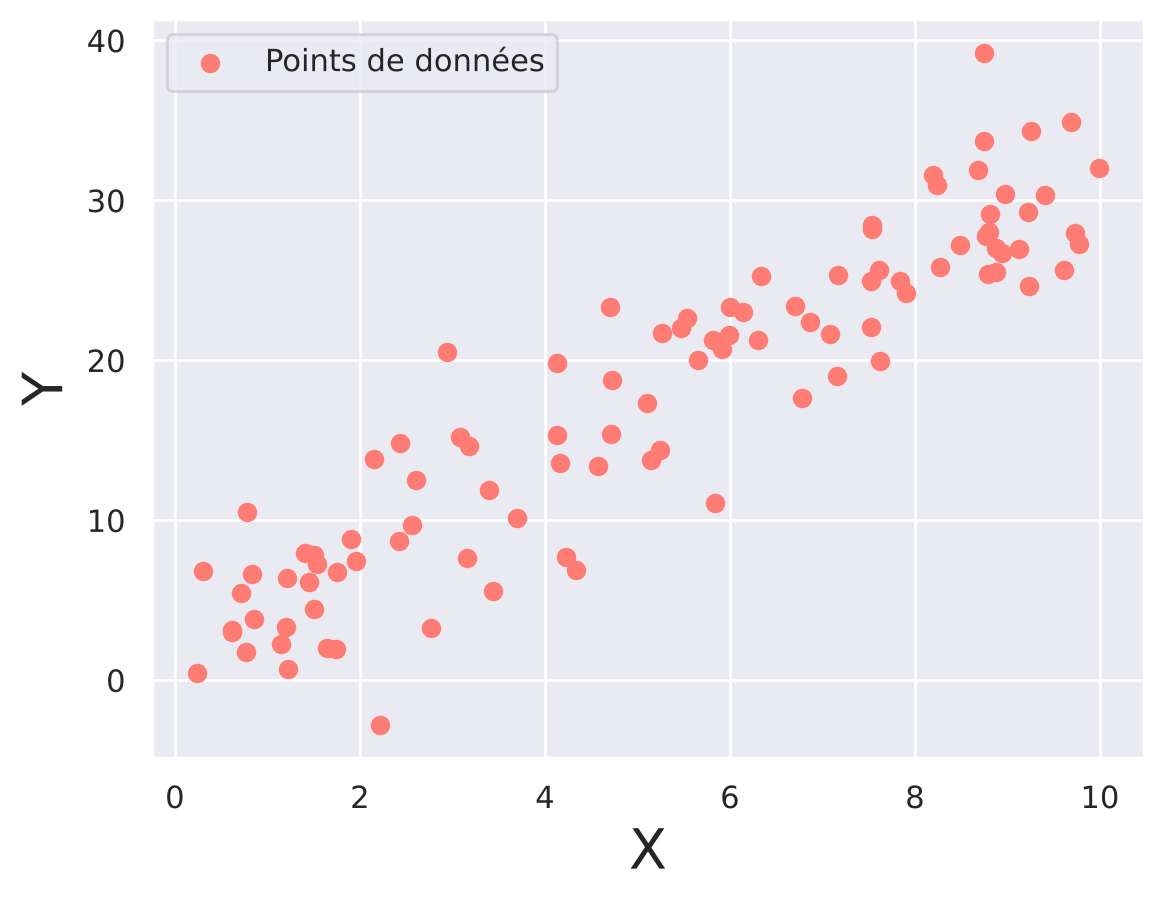

In [3]:
# Générer des données aléatoires
num_points = 100
X = np.random.rand(num_points, 1) * 10  # Variable explicative
noise = np.random.normal(0, 4, (num_points, 1))  # Bruit gaussien
y = 3 * X + 2 + noise  # Relation linéaire

# Tracer les données
plt.scatter(X, y, color=colors[0], label='Points de données')

plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()
plt.show()

On ajuste ensuite le modèle et on trace la droite. C'est le premier GLM de la série : **loi gaussienne**, **lien identité**.

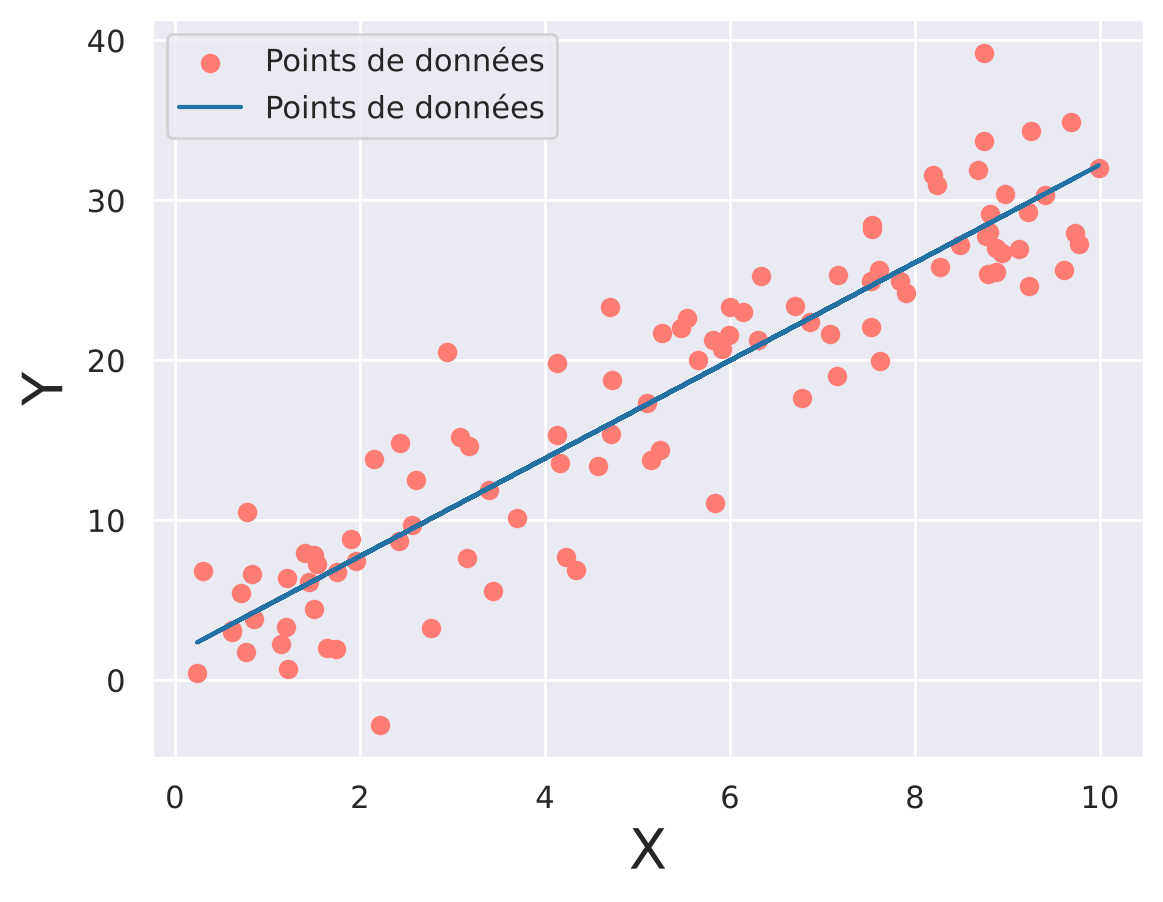

In [4]:
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

plt.scatter(X, y, color=colors[0], label='Points de données')
plt.plot(X, y_pred, color=colors[1], label='Points de données')

plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()
plt.show()

## 3. Régression logistique : quand la cible est binaire

Ici la cible vaut 0 ou 1. Une droite n'a aucun sens (elle sortirait de [0, 1]) : on a besoin d'un autre modèle. Voici les données : la classe 0 à gauche, la classe 1 à droite.

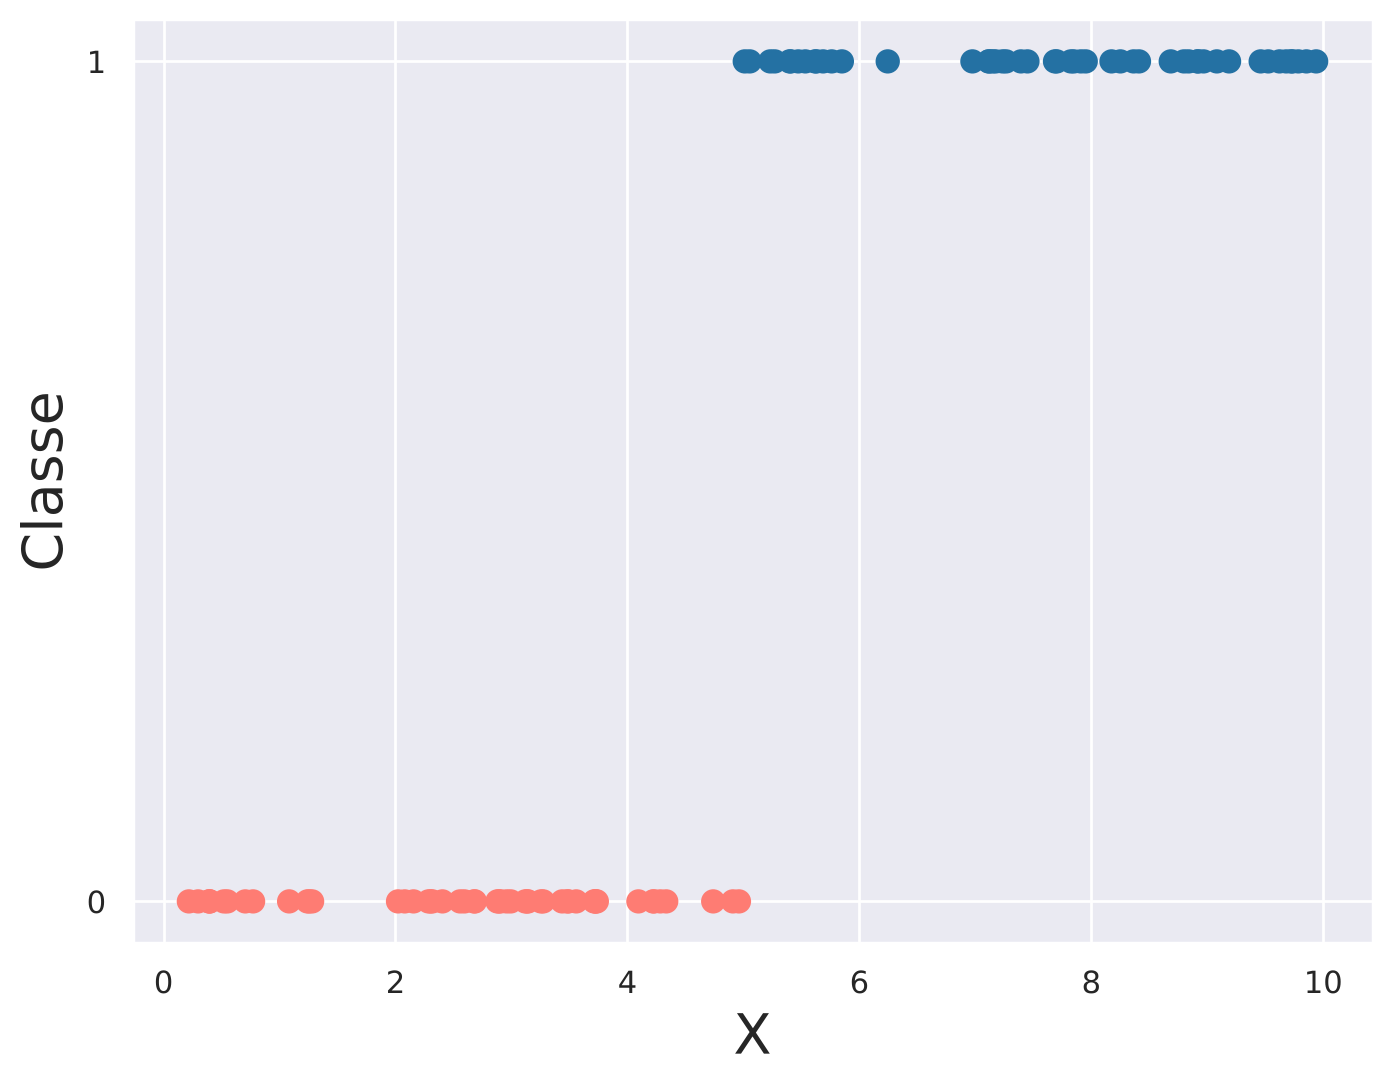

In [5]:
# Générer les données
num_points = 100
x_class_0 = np.random.rand(num_points // 2) * 5  # Points de données de la classe 0
x_class_1 = np.random.rand(num_points // 2) * 5 + 5  # Points de données de la classe 1
x = np.concatenate((x_class_0, x_class_1))  # Combiner les deux classes
y = np.concatenate((np.zeros(num_points // 2), np.ones(num_points // 2)))  # Étiquettes : 0 et 1

# Créer un graphique de dispersion
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, c=[colors[int(i)] for i in y], marker='o', s=60)
ax.set_xlabel('X'    , fontsize = 20)
ax.set_ylabel('Classe', fontsize = 20)
ax.set_yticks([0, 1])

plt.show()

On ajuste une régression logistique et on trace la probabilité prédite P(y = 1 | x). La courbe en S est la sigmoïde, qui joue ici le rôle de la **fonction de lien inverse** : **loi de Bernoulli**, **lien logit**.

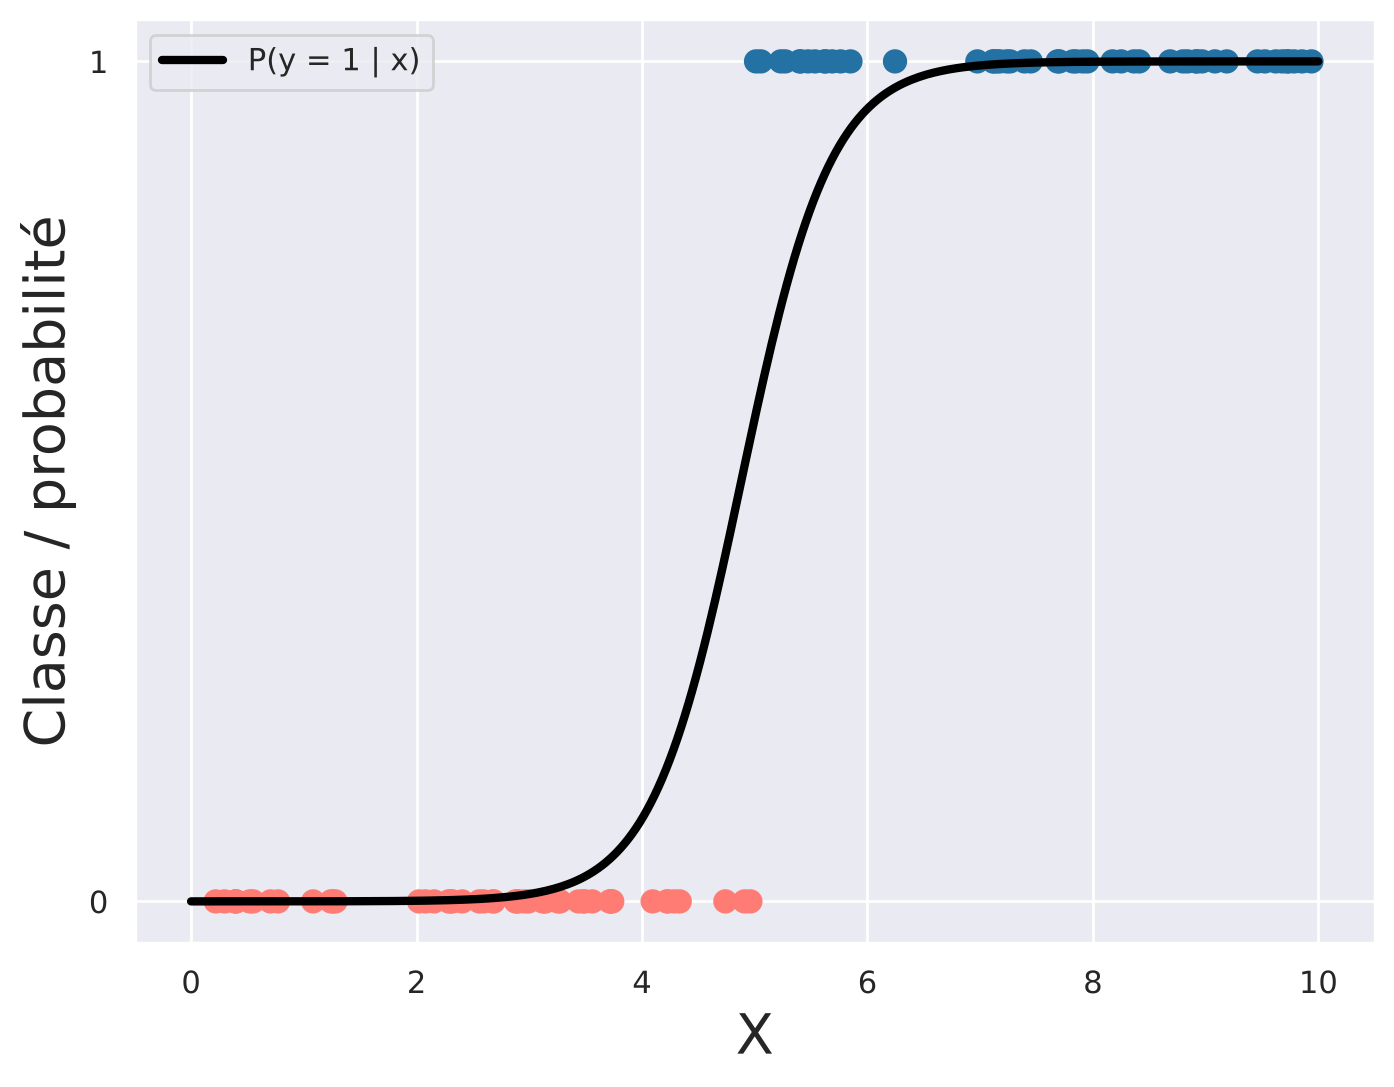

In [6]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression().fit(x.reshape(-1, 1), y)

x_grid = np.linspace(0, 10, 300).reshape(-1, 1)
proba_classe_1 = logreg.predict_proba(x_grid)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, c=[colors[int(i)] for i in y], marker='o', s=60)
ax.plot(x_grid, proba_classe_1, color='black', lw=3, label='P(y = 1 | x)')
ax.set_xlabel('X', fontsize=20)
ax.set_ylabel('Classe / probabilité', fontsize=20)
ax.set_yticks([0, 1])
ax.legend()
plt.show()

## 4. Régression de Poisson : quand la cible est un comptage

Nombre d'appels reçus, de clics, d'accidents… : des entiers positifs dont la variance grandit avec la moyenne. On simule des données où le logarithme de la moyenne est linéaire en x (θ = 2,5), puis on tire y selon une loi de Poisson.

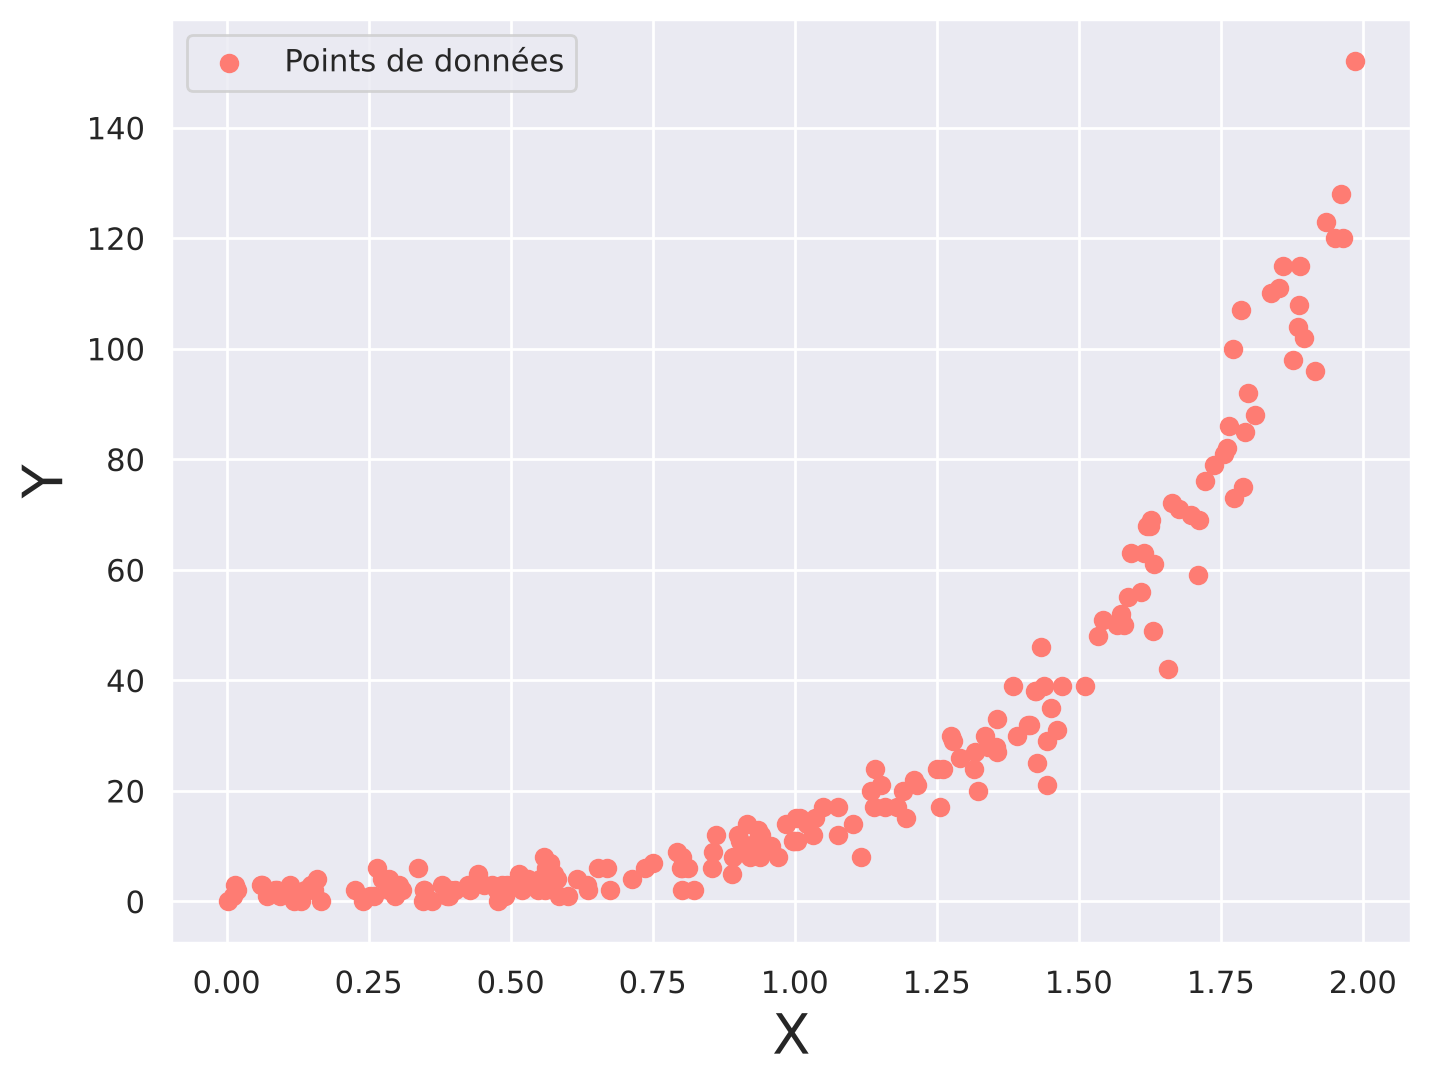

In [7]:
# Générer la variable prédictive X
num_points = 200
X = np.random.uniform(0, 2, num_points)

# Vraie valeur du paramètre pour la relation entre X et mean(u(x))
theta = 2.5

# Générer la variable de réponse y suivant une distribution de Poisson
mean_u = theta * X
y = np.random.poisson(np.exp(mean_u))

b = X.reshape(-1).argsort()
y = y[b]
X = X[b].reshape(-1,1)

# Créer un graphique de dispersion des données de régression de Poisson générées
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color=colors[0], label='Points de données')
plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()
plt.show()

### 4.1 Modéliser avec une régression de Poisson

**Loi de Poisson**, **lien logarithme** : la courbe suit la forme exponentielle des données.

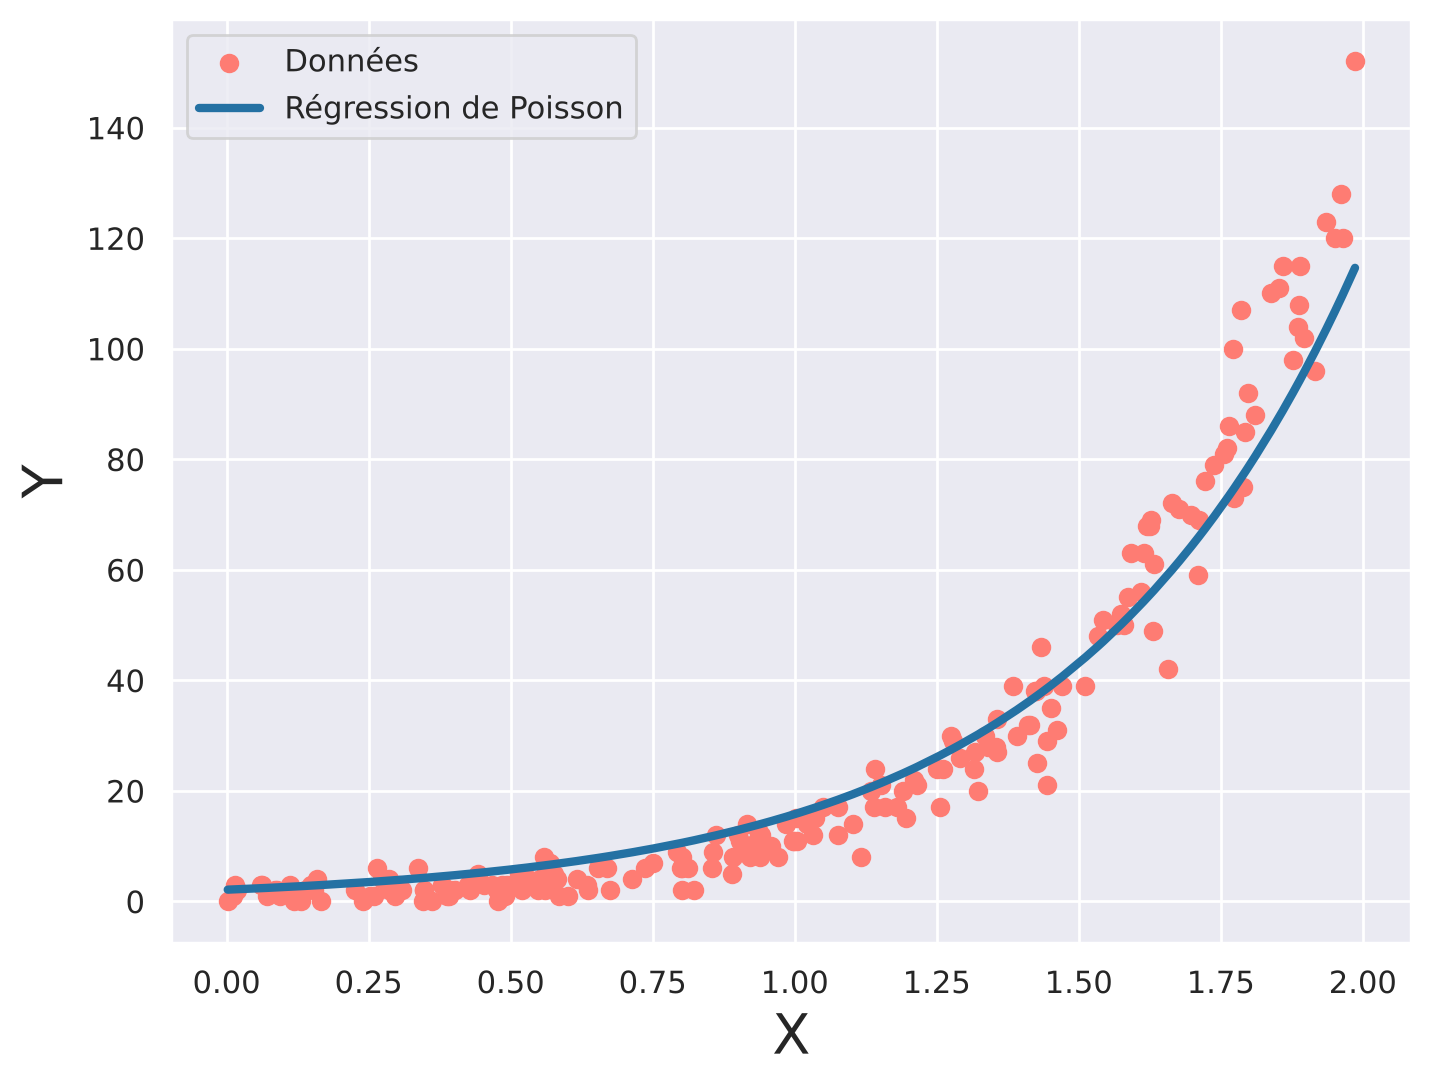

In [8]:
poisson_model = PoissonRegressor()
poisson_model.fit(X, y)

# Prédire avec le modèle entraîné
y_pred_poisson = poisson_model.predict(X)

# Tracer les données originales et l'ajustement de la régression
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color=colors[0], label='Données')  ## Régression de Poisson
plt.plot(X, y_pred_poisson, color=colors[1], label='Régression de Poisson', lw=3)

plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()

plt.show()

### 4.2 Pourquoi pas une simple régression linéaire ?

Pour comparer, on ajuste une droite sur les mêmes données. Elle passe à côté de la courbure et peut même prédire des valeurs négatives, alors qu'un comptage ne l'est jamais.

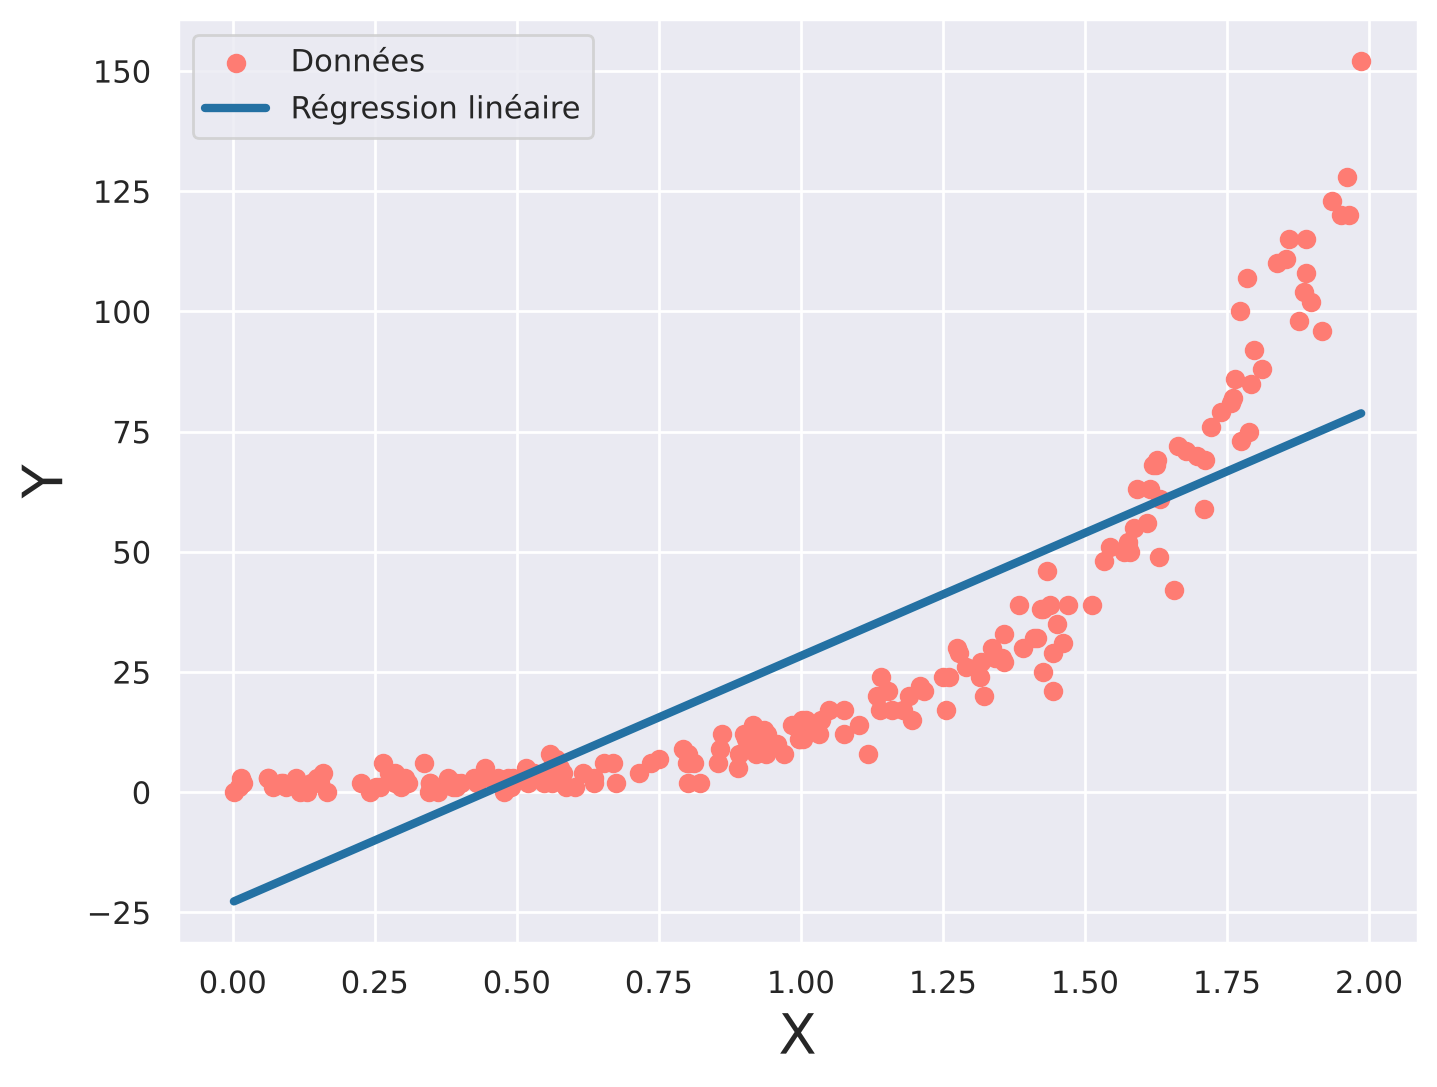

In [9]:
linear_model = LinearRegression()
linear_model.fit(X, y)

# Prédire avec le modèle de régression linéaire
y_pred_linear = linear_model.predict(X)

# Tracer les données originales et l'ajustement de la régression
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color=colors[0], label='Données')
plt.plot(X, y_pred_linear, color=colors[1], label='Régression linéaire', lw=3)

plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()

plt.show()

### 4.3 À quoi ressemble une loi de Poisson ?

Une loi de Poisson n'a qu'un paramètre λ (sa moyenne, qui est aussi sa variance). Quand λ est petit, la loi est asymétrique ; quand λ grandit, elle devient presque symétrique.

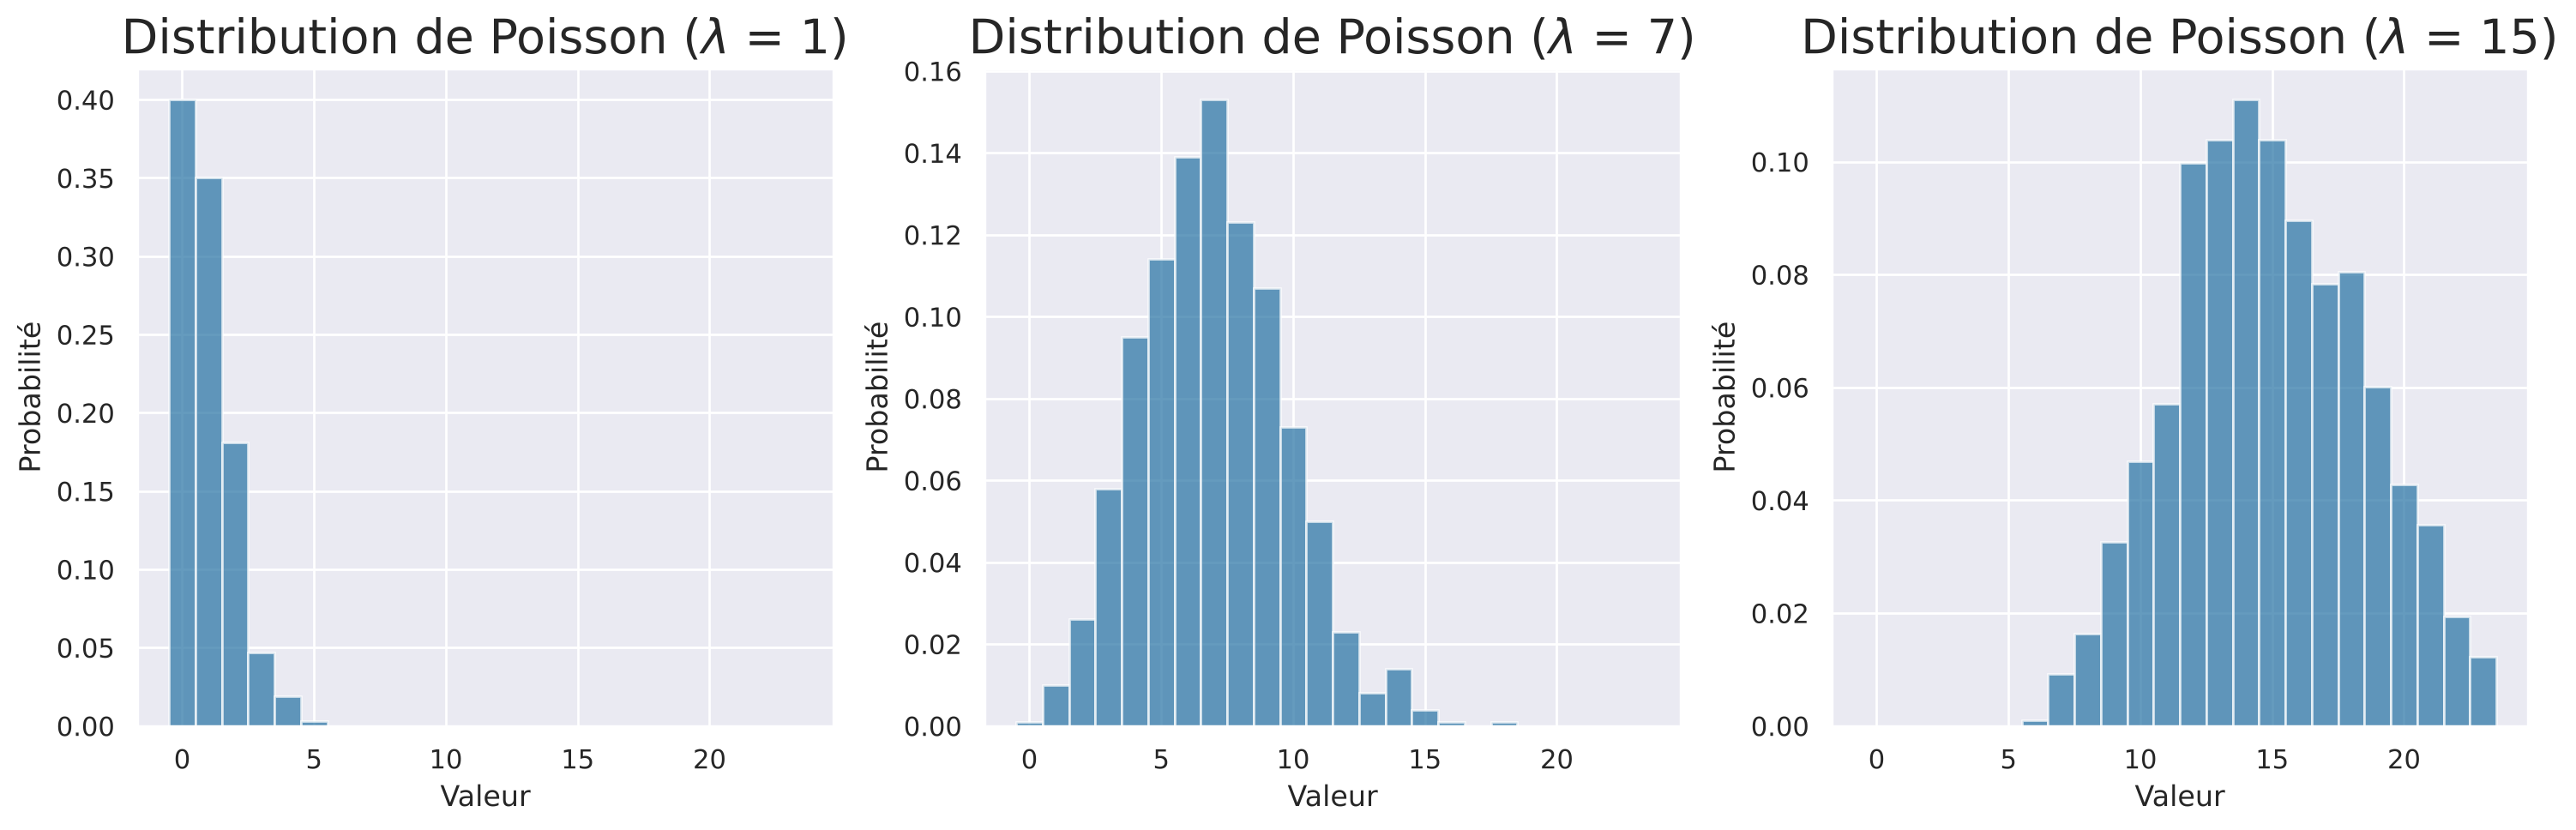

In [10]:
# Valeurs de la moyenne (lambda) pour la distribution de Poisson
mean_values = [1, 7, 15]

# Générer des points de données pour chaque moyenne
num_points = 1000
data = {mean: np.random.poisson(mean, num_points) for mean in mean_values}

# Créer des sous-graphiques avec des histogrammes
plt.figure(figsize=(15, 5))
for i, mean in enumerate(mean_values):
    plt.subplot(1, len(mean_values), i + 1)
    plt.hist(data[mean], bins=np.arange(0, 25) - 0.5, density=True, color=colors[1], alpha=0.7)
    plt.title(f'Distribution de Poisson ($\\lambda$ = {mean})', fontsize=20, )
    plt.xlabel('Valeur')
    plt.ylabel('Probabilité')
plt.tight_layout()
plt.show()

## 5. Un GLM sur mesure avec `statsmodels`

Et si ton problème ne rentre dans aucune case ? Les GLM te laissent choisir **séparément** la loi de la cible et la fonction de lien. Ici : une cible gaussienne dont la **moyenne** est exponentielle en x, c'est-à-dire un lien logarithme.

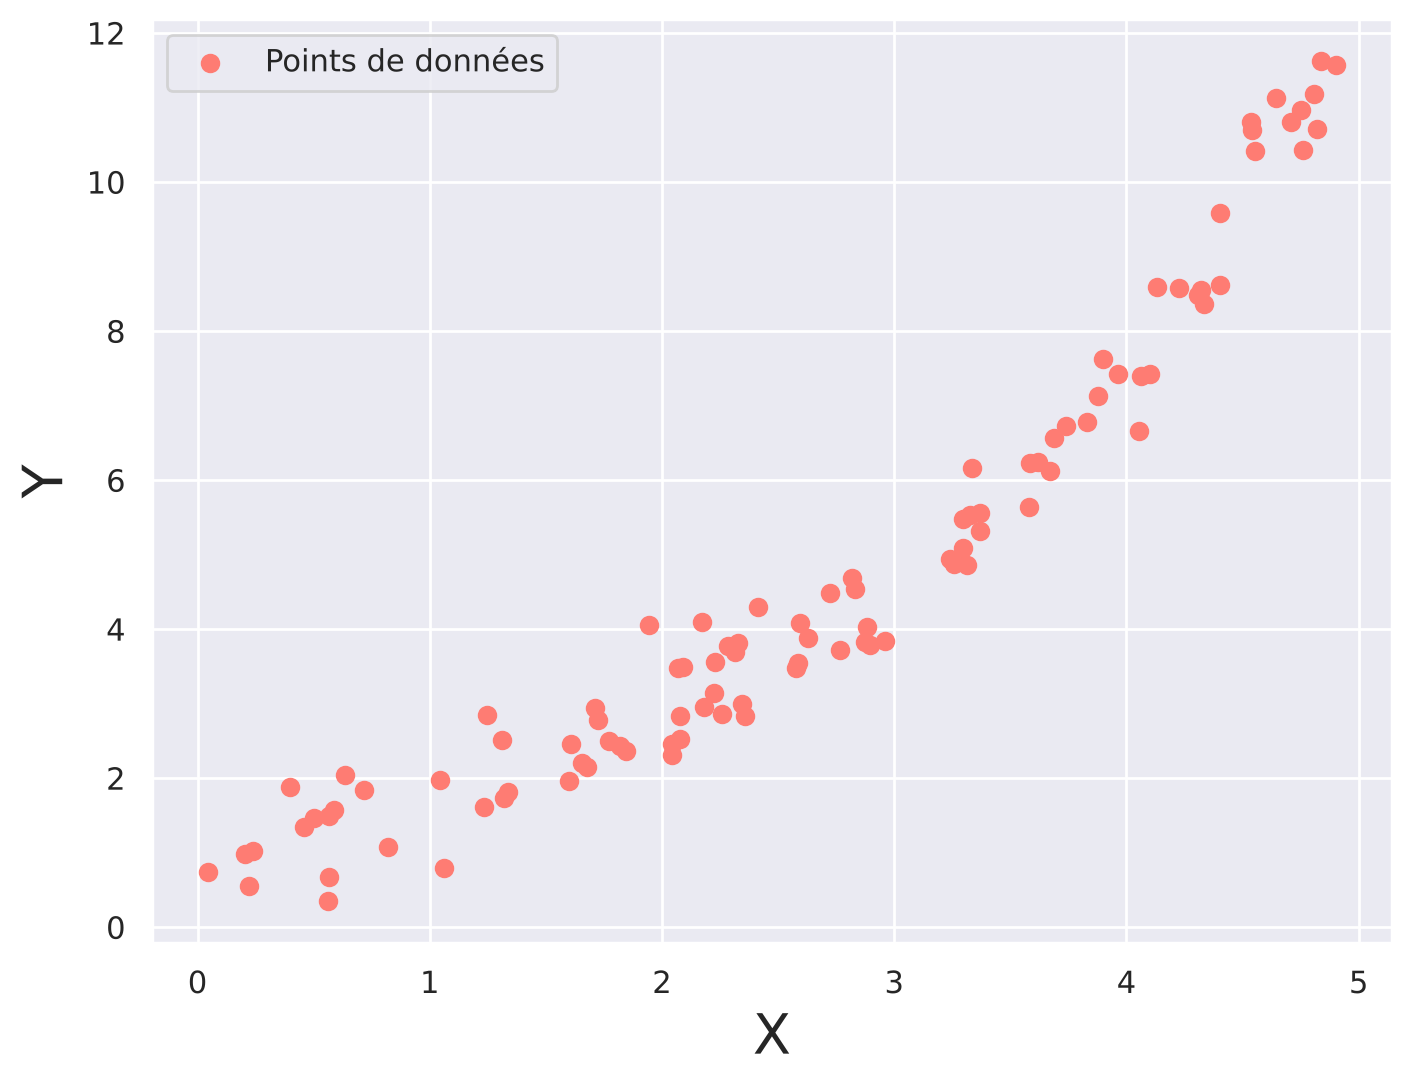

In [11]:
# Générer la variable prédictive X
num_points = 100
X = np.random.uniform(0, 5, num_points)

# Vraie valeur du paramètre pour la relation entre X et log(u(x))
theta = 0.5

# Générer la moyenne transformée logarithmiquement u(x)
log_mean_u = theta * X

# Générer la variable de réponse y à partir d'une distribution normale basée sur la moyenne transformée logarithmiquement
y = np.random.normal(np.exp(log_mean_u), scale=0.5)  # 'scale' représente l'écart-type

# Créer un graphique de dispersion des données générées
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color=colors[0], label='Points de données')
plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()
plt.show()

On passe à `statsmodels`, qui permet de spécifier la famille (ici `Gaussian`) et le lien (ici `Log`).

In [12]:
import statsmodels.api as sm

b = X.reshape(-1).argsort()
y = y[b]
X = X[b].reshape(-1,1)

# Spécifier le modèle GLM avec une famille gaussienne et un lien logarithmique
glm_model = sm.GLM(y, X, family=sm.families.Gaussian(link=sm.families.links.Log()))

On ajuste le modèle, puis on affiche le résumé complet : coefficients, erreurs standards, tests, déviance… Retrouve-tu le coefficient θ = 0,5 utilisé pour simuler les données ?

In [13]:
glm_results = glm_model.fit()

In [14]:
print(glm_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                  100
Model:                            GLM   Df Residuals:                       99
Model Family:                Gaussian   Df Model:                            0
Link Function:                    Log   Scale:                         0.22750
Method:                          IRLS   Log-Likelihood:                -67.363
Date:                Fri, 20 Nov 2026   Deviance:                       22.522
Time:                        16:22:51   Pearson chi2:                     22.5
No. Iterations:                     5   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.5043      0.002    244.491      0.0

Enfin, on prédit avec le modèle et on trace la courbe ajustée.

In [15]:
predicted_values = glm_results.predict(X)

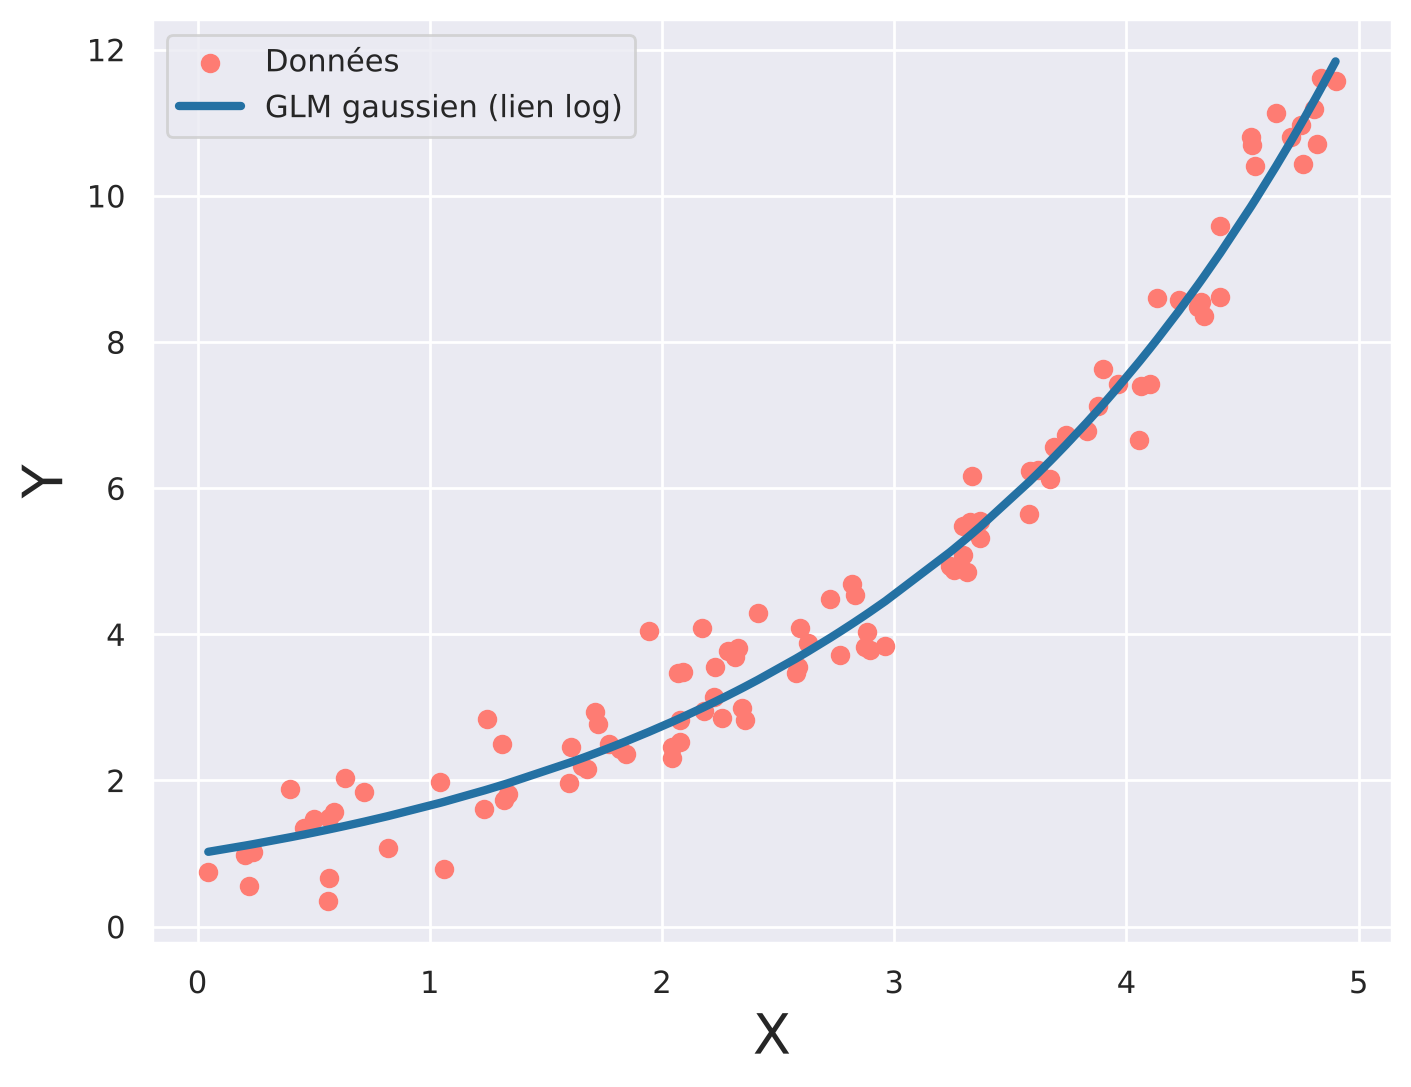

In [16]:
from sklearn.linear_model import PoissonRegressor

# Tracer les données originales et l'ajustement de la régression
plt.figure(figsize=(8, 6))
plt.scatter(X, y, color=colors[0], label='Données')
plt.plot(X, predicted_values, color=colors[1], label='GLM gaussien (lien log)', lw=3)

plt.xlabel('X', fontsize = 20)
plt.ylabel('Y', fontsize = 20)
plt.legend()
plt.show()

---

## Pour aller plus loin

- [Régression Linéaire : d'où viennent vraiment ses hypothèses ?](https://www.monshotdata.com/p/hypotheses-regression-lineaire) — les hypothèses que les GLM permettent de relâcher
- [Régression Logistique : Pourquoi la Sigmoïde (et pas une autre) ?](https://www.monshotdata.com/p/regression-logistique-sigmoide) — d'où vient le lien logit
- [Régression Logistique : Plongée dans la logique de la perte logarithmique](https://www.monshotdata.com/p/regression-logistique-perte-logarithmique) — comment on entraîne un GLM binaire